# Data Audit

Through this notebook, one is going to inspect the data quality of the dataset.

The dataset comes from NYC Taxi Records: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

The dataset is focused on the yellow taxi record of the database.

# Analysis Steps

1. shape
2. head()
3. info()
4. columns
5. dtypes
6. missing values
7. duplicates / uniqueness
8. numerical summaries
9. categorical distributions
10. date/time ranges
11. business-rule checks
12. foreign-key checks
13. outlier investigation
14. data-quality summary
15. define cleaning rules

## Set Up

In [26]:
# All the imports that will be used for this dataset

import pandas as pd
import matplotlib.pyplot as plt

## Loading the Data

In [27]:
yellow_trip_data = pd.read_parquet("../data/raw/yellow_tripdata_2026-01.parquet")
zones = pd.read_csv("../data/raw/taxi_zone_lookup.csv")

## Confirm that the dataset is loaded correctly

In [28]:
# Inspecting 10 random rows in the dataset

yellow_trip_data.sample(n=10)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
2244384,1,2026-01-27 19:05:14,2026-01-27 19:32:12,1.0,9.50,1.0,N,138,244,2,40.80,9.25,0.5,0.00,7.46,1.0,59.01,0.0,1.75,0.00
1310830,1,2026-01-16 08:47:22,2026-01-16 08:54:42,1.0,1.30,1.0,N,107,162,1,9.30,3.25,0.5,4.20,0.00,1.0,18.25,2.5,0.00,0.75
1885252,2,2026-01-22 17:09:02,2026-01-22 17:22:48,1.0,1.32,1.0,N,162,230,1,12.80,2.50,0.5,4.01,0.00,1.0,24.06,2.5,0.00,0.75
1149028,1,2026-01-14 16:55:22,2026-01-14 17:04:57,1.0,1.80,1.0,N,238,143,1,10.70,5.75,0.5,4.50,0.00,1.0,22.45,2.5,0.00,0.75
2522489,2,2026-01-30 19:15:08,2026-01-30 19:18:38,1.0,0.73,1.0,N,148,232,1,5.80,2.50,0.5,2.61,0.00,1.0,15.66,2.5,0.00,0.75
296781,2,2026-01-05 07:42:23,2026-01-05 07:47:12,2.0,0.68,1.0,N,236,237,1,6.50,0.00,0.5,2.10,0.00,1.0,12.60,2.5,0.00,0.00
3529161,2,2026-01-28 07:28:00,2026-01-28 07:38:14,NaN,2.59,NaN,NaN,232,88,0,53.75,0.00,0.5,0.00,0.00,1.0,69.92,NaN,NaN,0.75
999188,2,2026-01-13 04:31:11,2026-01-13 04:35:15,1.0,0.74,1.0,N,237,141,1,6.50,1.00,0.5,2.30,0.00,1.0,13.80,2.5,0.00,0.00
599559,2,2026-01-08 17:29:47,2026-01-08 17:57:34,1.0,2.20,1.0,N,162,224,1,24.00,2.50,0.5,6.25,0.00,1.0,37.50,2.5,0.00,0.75
3666403,1,2026-01-30 23:30:13,2026-01-30 23:43:54,NaN,1.30,NaN,NaN,68,170,0,15.63,0.00,0.5,0.00,0.00,1.0,28.93,NaN,NaN,0.75


In [29]:
# Inspecting column names, numbers, and also their data types

yellow_trip_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3724889 entries, 0 to 3724888
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee            float64   

In [30]:
# Inspecting the shape of the dataset
yellow_trip_data.shape

(3724889, 20)

## Initial Observations:

- Number of rows: 3724889
- Number of columns: 20
- Unit of observation: an individual taxi trip.
- Initial data quality concerns: There exist some data type concerns in the information tab. This will be further investigated later.

## Column Inventory

In [31]:
yellow_trip_data.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'Airport_fee',
 'cbd_congestion_fee']

Data Dictionary

* VendorID: A code indicating the TPEP provider that provided the record.
    1 = Creative Mobile Technologies, LLC
    2 = Curb Mobility, LLC
    6 = Myle Technologies Inc
    7 = Helix

* tpep_pickup_datetime : The date and time when the meter was engaged.
* tpep_dropoff_datetime: The date and time when the meter was disengaged. 
* passenger_count: The number of passengers in the vehicle. 
* trip_distance: The elapsed trip distance in miles reported by the taximeter.
* RatecodeID: The final rate code in effect at the end of the trip.
    1 = Standard rate
    2 = JFK
    3 = Newark
    4 = Nassau or Westchester
    5 = Negotiated fare
    6 = Group ride
    99 = Null/unknown
* store_and_fwd_flag: This flag indicates whether the trip record was held in vehicle memory before
    sending to the vendor, aka “store and forward,” because the vehicle did not
    have a connection to the server.
    Y = store and forward trip
    N = not a store and forward trip
* PULocationID: TLC Taxi Zone in which the taximeter was engaged.
* DOLocationID: TLC Taxi Zone in which the taximeter was disengaged.
* payment_type: A numeric code signifying how the passenger paid for the trip.
    0 = Flex Fare trip
    1 = Credit card
    2 = Cash
    3 = No charge
    4 = Dispute
    5 = Unknown
    6 = Voided trip
* fare_amount: The time-and-distance fare calculated by the meter. For additional
    information on the following columns, see
    https://www.nyc.gov/site/tlc/passengers/taxi-fare.page
* extra: Miscellaneous extras and surcharges.
* mta_tax: Tax that is automatically triggered based on the metered rate in use
* tip_amount: Tip amount – This field is automatically populated for credit card tips. Cash
    tips are not included.
* tolls_amount: Total amount of all tolls paid in trip.
* improvement_surcharge: Improvement surcharge assessed trips at the flag drop. The improvement
    surcharge began being levied in 2015.
* total_amount: The total amount charged to passengers. Does not include cash tips.
* congestion_surcharge: Total amount collected in trip for NYS congestion surcharge.
* airport_fee: For pick up only at LaGuardia and John F. Kennedy Airports.
* cbd_congestion_fee: Per-trip charge for MTA's Congestion Relief Zone starting Jan. 5, 2025

## Data Types

In [32]:
yellow_trip_data.dtypes

VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag                  str
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
cbd_congestion_fee              float64
dtype: object

### Data Types Report

There is one column might not be in the correct data types

* Passenger_count is displayed in float64 (This should be in int32 since passenger is a discrete variable)

## Missing Values

In [33]:
yellow_trip_data.isna().sum()

VendorID                       0
tpep_pickup_datetime           0
tpep_dropoff_datetime          0
passenger_count          1088058
trip_distance                  0
RatecodeID               1088058
store_and_fwd_flag       1088058
PULocationID                   0
DOLocationID                   0
payment_type                   0
fare_amount                    0
extra                          0
mta_tax                        0
tip_amount                     0
tolls_amount                   0
improvement_surcharge          0
total_amount                   0
congestion_surcharge     1088058
Airport_fee              1088058
cbd_congestion_fee             0
dtype: int64

In [34]:
missing_columns = [
    "passenger_count",
    "RatecodeID",
    "store_and_fwd_flag",
    "congestion_surcharge",
    "Airport_fee"
]

yellow_trip_data[missing_columns].isna().all(axis=1).sum()

np.int64(1088058)

In [35]:
yellow_trip_data[missing_columns].isna().all(axis=1).sum() / yellow_trip_data.shape[0]

np.float64(0.2921048117138524)

That's about 30% of the observations that are missing these columns of information.

In [36]:
missing_mask = yellow_trip_data[missing_columns].isna().all(axis=1)

yellow_trip_data.loc[missing_mask]

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
2636831,2,2026-01-01 00:28:47,2026-01-01 00:49:30,NaN,10.58,NaN,NaN,43,200,0,82.01,0.0,0.5,0.0,3.18,1.0,89.19,NaN,NaN,0.00
2636832,2,2026-01-01 00:54:24,2026-01-01 01:15:01,NaN,11.04,NaN,NaN,200,51,0,51.77,0.0,0.5,0.0,0.00,1.0,53.27,NaN,NaN,0.00
2636833,2,2026-01-01 00:12:31,2026-01-01 00:41:02,NaN,4.25,NaN,NaN,142,234,0,32.17,0.0,0.5,0.0,0.00,1.0,36.92,NaN,NaN,0.75
2636834,2,2026-01-01 00:48:56,2026-01-01 01:08:00,NaN,2.05,NaN,NaN,90,114,0,18.29,0.0,0.5,1.0,0.00,1.0,24.04,NaN,NaN,0.75
2636835,2,2026-01-01 00:32:09,2026-01-01 00:41:05,NaN,0.97,NaN,NaN,237,163,0,15.02,0.0,0.5,0.0,0.00,1.0,22.77,NaN,NaN,0.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3724884,2,2026-01-31 23:26:00,2026-01-31 23:39:16,NaN,1.62,NaN,NaN,237,161,0,17.09,0.0,0.5,0.0,0.00,1.0,21.84,NaN,NaN,0.75
3724885,2,2026-01-31 23:33:53,2026-01-31 23:34:07,NaN,0.00,NaN,NaN,42,42,0,23.19,0.0,0.5,0.0,0.00,1.0,24.69,NaN,NaN,0.00
3724886,2,2026-01-31 23:40:23,2026-01-31 23:56:10,NaN,6.84,NaN,NaN,137,69,0,29.21,0.0,0.5,0.0,0.00,1.0,33.96,NaN,NaN,0.75
3724887,2,2026-01-31 23:10:21,2026-01-31 23:20:00,NaN,1.53,NaN,NaN,137,162,0,19.19,0.0,0.5,0.0,0.00,1.0,23.94,NaN,NaN,0.75


In [37]:
yellow_trip_data.loc[missing_mask]['VendorID'].value_counts()

VendorID
2    944635
1    139406
6      4017
Name: count, dtype: int64

In [38]:
yellow_trip_data[missing_mask]['payment_type'].value_counts()

payment_type
0    1088058
Name: count, dtype: int64

In [39]:
yellow_trip_data[
    yellow_trip_data['payment_type'] == 0
][missing_columns].isna().all(axis=1).value_counts()

True    1088058
Name: count, dtype: int64

### Missing Values Report:

There are five columns that have missing values:
* passenger_count
* RatecodeID 
* store_and_fwd_flag
* congestion_surcharge
* Airport_fee

They all miss same amount of values which is 1088058 rows. This means that there is a missing pattern in the data.

After some further investigation. One found out that for all of the rows where these data is missing. It is correctly displayed that payment type is 0 which indicates for flex fare trip.

Definition of flex fare trip:
a ride booked through a licensed e-hail app (such as Curb or Arro) that provides an upfront, fixed, non-metered binding price before you confirm the ride

Therefore when we are doing analysis regarding things that invovles these five columns, we ought not include the observations that have flex fare trip.

# Check for duplicates & Uniqueness

In [40]:
# Check for duplicates in the data

duplicated_count = yellow_trip_data.duplicated().sum()
duplicated_count

np.int64(0)

Duplicate check has been passed since there are no exact same observations across different rows.

In [41]:
# Check for uniqueness in the data

yellow_trip_data.nunique()

VendorID                       4
tpep_pickup_datetime     1757191
tpep_dropoff_datetime    1755995
passenger_count               10
trip_distance               4777
RatecodeID                     7
store_and_fwd_flag             2
PULocationID                 262
DOLocationID                 260
payment_type                   5
fare_amount                12867
extra                         45
mta_tax                        6
tip_amount                  4326
tolls_amount                1495
improvement_surcharge          4
total_amount               21228
congestion_surcharge           3
Airport_fee                    8
cbd_congestion_fee             3
dtype: int64

In [42]:
# Check for passenger Count in the data

yellow_trip_data["passenger_count"].value_counts()

passenger_count
1.0    2150994
2.0     334370
3.0      72864
4.0      49738
0.0      14787
5.0       9184
6.0       4887
8.0          4
7.0          2
9.0          1
Name: count, dtype: int64

In [43]:
yellow_trip_data[yellow_trip_data['passenger_count'] > 4]

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
312,2,2026-01-01 00:09:20,2026-01-01 00:13:14,5.0,0.59,1.0,N,238,239,1,5.8,1.0,0.5,2.16,0.0,1.0,12.96,2.5,0.0,0.00
334,2,2026-01-01 00:17:54,2026-01-01 00:29:58,5.0,1.17,1.0,N,107,170,1,12.1,1.0,0.5,3.00,0.0,1.0,20.85,2.5,0.0,0.75
335,2,2026-01-01 00:48:18,2026-01-01 00:54:29,5.0,1.01,1.0,N,114,107,1,7.9,1.0,0.5,4.10,0.0,1.0,17.75,2.5,0.0,0.75
684,2,2026-01-01 00:28:24,2026-01-01 00:41:05,5.0,1.86,1.0,N,142,236,1,13.5,1.0,0.5,3.70,0.0,1.0,22.20,2.5,0.0,0.00
685,2,2026-01-01 00:42:26,2026-01-01 01:12:47,5.0,5.21,1.0,N,43,249,1,30.3,1.0,0.5,5.00,0.0,1.0,41.05,2.5,0.0,0.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2633979,2,2026-01-31 23:06:05,2026-01-31 23:24:37,6.0,2.90,1.0,N,90,237,2,19.1,1.0,0.5,0.00,0.0,1.0,24.85,2.5,0.0,0.75
2635206,2,2026-01-31 23:09:36,2026-01-31 23:26:23,6.0,7.20,1.0,N,142,244,1,30.3,1.0,0.5,7.21,0.0,1.0,43.26,2.5,0.0,0.75
2635306,2,2026-01-31 23:19:32,2026-01-31 23:26:51,5.0,0.66,1.0,N,79,4,1,7.9,1.0,0.5,3.00,0.0,1.0,16.65,2.5,0.0,0.75
2635307,2,2026-01-31 23:28:16,2026-01-31 23:34:30,5.0,0.70,1.0,N,4,79,1,7.2,1.0,0.5,2.59,0.0,1.0,15.54,2.5,0.0,0.75


There are interesting things with the passenger count happening in the data. Legally, with the driver counted there can be only 4 passenger max in a yellow cab and there are 14078 observations that have more than 4 passengers in the cab which means that there are some outliers in the data.

## Numerical Summaries

In [44]:
pd.set_option("display.float_format", lambda x: f"{x:,.2f}") # Change the display format to two decimals

yellow_trip_data.describe()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
count,"3,724,889.00",3724889,3724889,"2,636,831.00","3,724,889.00","2,636,831.00","3,724,889.00","3,724,889.00","3,724,889.00","3,724,889.00","3,724,889.00","3,724,889.00","3,724,889.00","3,724,889.00","3,724,889.00","3,724,889.00","2,636,831.00","2,636,831.00","3,724,889.00"
mean,1.87,2026-01-17 01:44:52.106518,2026-01-17 02:02:03.696138,1.26,6.46,5.22,161.44,160.99,0.85,20.80,1.02,0.48,2.61,0.50,0.95,29.18,2.15,0.15,0.52
min,1.00,2025-12-31 23:57:29,2025-12-31 23:57:32,0.00,0.00,1.00,1.00,1.00,0.00,"-2,555.20",-7.50,-0.50,-88.88,-94.50,-1.00,"-2,560.20",-2.50,-1.75,-0.75
25%,2.00,2026-01-09 17:51:59,2026-01-09 18:08:47,1.00,1.00,1.00,114.00,107.00,0.00,10.00,0.00,0.50,0.00,0.00,1.00,17.00,2.50,0.00,0.00
50%,2.00,2026-01-16 21:20:56,2026-01-16 21:36:14,1.00,1.81,1.00,161.00,162.00,1.00,15.60,0.00,0.50,2.00,0.00,1.00,23.05,2.50,0.00,0.75
75%,2.00,2026-01-24 07:25:11,2026-01-24 07:40:22,1.00,3.73,1.00,233.00,234.00,1.00,26.10,2.50,0.50,3.71,0.00,1.00,33.83,2.50,0.00,0.75
max,7.00,2026-02-01 00:45:01,2026-02-01 23:35:31,9.00,"269,097.48",99.00,265.00,265.00,4.00,"2,555.20",17.46,4.75,766.00,122.22,1.00,"2,560.20",2.50,26.75,0.75
std,0.70,NaN,NaN,0.67,648.89,19.65,67.07,71.04,0.71,18.93,1.71,0.11,3.92,2.13,0.27,22.59,0.94,0.53,0.36


Interesting time is that the pick up time includes 2025-12-31 and also 2026-02-01. The dataset description should only include rides that are within Janurary of 2026 but here we are finding data that are out of bounds.

There are also trip distance that are zero miles which requires further investigation. And also the largest trip distance is very large (269,097.48) which requires further investigation.

The minimum fare_amount if negative -2555.20 which requires further investigation.

Same thing applies to extra, mta_tax, tip_amount, improvement_surcharge, total_amount, congestion_surcharge, Airport_free, cbd_congestion_fee which are negative numbers which logically does not make sense.

There needs to be more investigation into the minimum observations of these data.

## Categorical Distribution Check

In [45]:
# Saving all categorical columns

categorical_columns = [
    "VendorID",
    "payment_type",
    "RatecodeID",
    "store_and_fwd_flag"
]

for col in categorical_columns:
    print(f"\n---{col}---")
    print(yellow_trip_data[col].value_counts(dropna=False))


---VendorID---
VendorID
2    2965742
1     710425
7      44705
6       4017
Name: count, dtype: int64

---payment_type---
payment_type
1    2249747
0    1088058
2     314043
4      56400
3      16641
Name: count, dtype: int64

---RatecodeID---
RatecodeID
1.00     2390495
NaN      1088058
99.00     110864
2.00       83592
5.00       32030
3.00       11541
4.00        8304
6.00           5
Name: count, dtype: int64

---store_and_fwd_flag---
store_and_fwd_flag
N      2634494
NaN    1088058
Y         2337
Name: count, dtype: int64


In [46]:
# Distribution in percentages for vendor ID
counts = yellow_trip_data["VendorID"].value_counts(dropna=False)
percentage = yellow_trip_data["VendorID"].value_counts(normalize=True, dropna=False)

result = pd.DataFrame(
    {"Counts" : counts,
    "Percentages" : percentage}
)

result

,Counts,Percentages
VendorID,,
2,2965742,0.80
1,710425,0.19
7,44705,0.01
6,4017,0.00


<Axes: xlabel='VendorID'>

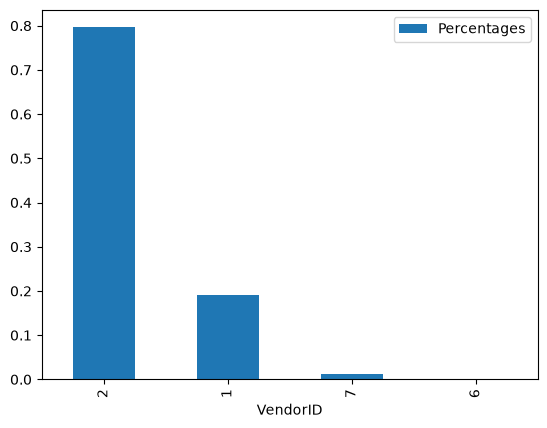

In [47]:
result.plot(kind="bar", y="Percentages")

Most rides are vendor ID 2 which is Curb Mobility.

In [48]:
counts = yellow_trip_data["payment_type"].value_counts(dropna=False)
percentage = yellow_trip_data["payment_type"].value_counts(normalize=True, dropna=False)

result = pd.DataFrame(
    {"Counts" : counts,
    "Percentages" : percentage}
)

result

,Counts,Percentages
payment_type,,
1,2249747,0.60
0,1088058,0.29
2,314043,0.08
4,56400,0.02
3,16641,0.00


In [49]:
counts = yellow_trip_data["RatecodeID"].value_counts(dropna=False)
percentage = yellow_trip_data["RatecodeID"].value_counts(normalize=True, dropna=False)

result = pd.DataFrame(
    {"Counts" : counts,
    "Percentages" : percentage}
)

result

,Counts,Percentages
RatecodeID,,
1.00,2390495,0.64
NaN,1088058,0.29
99.00,110864,0.03
2.00,83592,0.02
5.00,32030,0.01
3.00,11541,0.00
4.00,8304,0.00
6.00,5,0.00


In [50]:
counts = yellow_trip_data["store_and_fwd_flag"].value_counts(dropna=False)
percentage = yellow_trip_data["store_and_fwd_flag"].value_counts(normalize=True, dropna=False)

result = pd.DataFrame(
    {"Counts" : counts,
    "Percentages" : percentage}
)

result

,Counts,Percentages
store_and_fwd_flag,,
N,2634494,0.71
NaN,1088058,0.29
Y,2337,0.00


## Datetime Ranges Check

In [51]:
yellow_trip_data[["tpep_pickup_datetime", "tpep_dropoff_datetime"]].agg(["min", "max"])

,tpep_pickup_datetime,tpep_dropoff_datetime
min,2025-12-31 23:57:29,2025-12-31 23:57:32
max,2026-02-01 00:45:01,2026-02-01 23:35:31


There are some pick up times and drop off times outside of the janurary range.

In [52]:
start_date = pd.Timestamp("2026-01-01")
end_date = pd.Timestamp("2026-02-01")

outside_january_pickup = yellow_trip_data[(yellow_trip_data['tpep_pickup_datetime'] < start_date) | (yellow_trip_data['tpep_pickup_datetime'] >= end_date)]
outside_january_pickup

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
980,2,2025-12-31 23:57:29,2025-12-31 23:57:32,2.00,0.01,2.00,N,132,264,3,-70.00,0.00,-0.50,0.00,0.00,-1.00,-71.50,0.00,0.00,0.00
981,2,2025-12-31 23:57:29,2025-12-31 23:57:32,2.00,0.01,2.00,N,132,264,3,70.00,0.00,0.50,0.00,0.00,1.00,71.50,0.00,0.00,0.00
982,2,2025-12-31 23:58:58,2026-01-01 01:04:39,2.00,40.14,3.00,N,132,1,2,167.20,1.00,0.00,0.00,27.00,1.00,198.70,0.00,1.75,0.75
1404,2,2025-12-31 23:57:54,2026-01-01 00:09:36,1.00,2.00,1.00,N,164,144,1,12.80,1.00,0.50,2.00,0.00,1.00,20.55,2.50,0.00,0.75
2289,2,2025-12-31 23:59:06,2026-01-01 00:16:43,1.00,0.43,1.00,N,163,48,2,14.90,1.00,0.50,0.00,0.00,1.00,20.65,2.50,0.00,0.75
5181,2,2025-12-31 23:58:45,2026-01-01 00:07:12,1.00,1.68,1.00,N,113,4,1,10.70,1.00,0.50,2.00,0.00,1.00,18.45,2.50,0.00,0.75
2635466,2,2026-02-01 00:45:01,2026-02-01 01:03:08,1.00,1.78,1.00,N,79,249,1,15.60,1.00,0.50,5.34,0.00,1.00,26.69,2.50,0.00,0.75


7 observations have pick up time that are outside of the Janurary time window.

In [53]:
outside_january_dropoff = yellow_trip_data[(yellow_trip_data['tpep_dropoff_datetime'] < start_date) | (yellow_trip_data['tpep_dropoff_datetime'] >= end_date)]
outside_january_dropoff

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
980,2,2025-12-31 23:57:29,2025-12-31 23:57:32,2.00,0.01,2.00,N,132,264,3,-70.00,0.00,-0.50,0.00,0.00,-1.00,-71.50,0.00,0.00,0.00
981,2,2025-12-31 23:57:29,2025-12-31 23:57:32,2.00,0.01,2.00,N,132,264,3,70.00,0.00,0.50,0.00,0.00,1.00,71.50,0.00,0.00,0.00
2551488,2,2026-01-31 01:52:10,2026-02-01 09:31:00,1.00,88.36,1.00,N,148,193,2,0.00,0.00,-0.50,0.00,0.00,-1.00,-1.50,0.00,0.00,0.00
2551489,2,2026-01-31 01:52:10,2026-02-01 09:31:00,1.00,88.36,1.00,N,148,193,2,0.00,0.00,0.50,0.00,0.00,1.00,1.50,0.00,0.00,0.00
2551896,2,2026-01-31 01:48:19,2026-02-01 01:42:04,1.00,0.69,1.00,N,68,186,1,5.80,1.00,0.50,0.00,0.00,1.00,11.55,2.50,0.00,0.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3724864,2,2026-01-31 23:57:18,2026-02-01 00:25:27,NaN,3.72,NaN,NaN,141,158,0,35.22,0.00,0.50,0.00,0.00,1.00,39.97,NaN,NaN,0.75
3724868,2,2026-01-31 23:38:40,2026-02-01 00:03:09,NaN,3.15,NaN,NaN,49,36,0,49.26,0.00,0.50,0.00,0.00,1.00,55.83,NaN,NaN,0.00
3724874,2,2026-01-31 23:54:59,2026-02-01 00:35:58,NaN,11.40,NaN,NaN,237,97,0,51.21,0.00,0.50,0.00,0.00,1.00,55.96,NaN,NaN,0.75
3724876,2,2026-01-31 23:45:13,2026-02-01 00:14:59,NaN,4.64,NaN,NaN,233,24,0,40.21,0.00,0.50,0.00,0.00,1.00,51.70,NaN,NaN,0.75


There are many more observations that have drop off times that are outside of the january time frame window. Though only two obervations have drop off date time that are in December 31st.

## Business Rule Checks

In [54]:
# Check for pick up time so that no drop off time is before pick up time

yellow_trip_data[(yellow_trip_data['tpep_dropoff_datetime'] < yellow_trip_data['tpep_pickup_datetime'])]

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
1465434,1,2026-01-17 19:30:00,2026-01-17 19:18:18,1.00,16.50,99.00,N,46,86,1,66.50,0.00,0.50,0.00,0.00,0.00,67.00,0.00,0.00,0.00


There is one place where the drop off time happens before the pick up time

In [55]:
# Check for passenger count should be reasonable

yellow_trip_data[(yellow_trip_data['passenger_count'] <= 0) | (yellow_trip_data['passenger_count'] >= 6)]['passenger_count'].value_counts()

passenger_count
0.00    14787
6.00     4887
8.00        4
7.00        2
9.00        1
Name: count, dtype: int64

There are a couple of interesting note. There are 14787 trips where there are no passengers. And there are 4887 trips that have 6 passengers. There are also 4 trips with 8 passengers and 2 trips with 7 passengers and also 1 trip with 9 passengers. These are interesting information worthy of our attention.

In [56]:
# Trip distance should be positive
yellow_trip_data[yellow_trip_data['trip_distance'] < 0]

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee


In [57]:
yellow_trip_data['trip_distance'].eq(0).sum()

np.int64(125738)

There are no trips where the distance travelled is less than 0 miles, but there are 125738 trips that have 0 miles of travelling distance.

In [58]:
# Check for money columns

money_columns = [
    'fare_amount',
    'extra',
    'mta_tax',
    'tip_amount',
    'tolls_amount',
    'improvement_surcharge',
    'total_amount',
    'congestion_surcharge',
    'Airport_fee',
    'cbd_congestion_fee'
]

negative_counts = (
    yellow_trip_data[money_columns]
    .lt(0)
    .sum()
)

negative_counts

fare_amount              39463
extra                    20035
mta_tax                  37730
tip_amount                  67
tolls_amount              3391
improvement_surcharge    39732
total_amount             39984
congestion_surcharge     30448
Airport_fee               9225
cbd_congestion_fee       25197
dtype: int64

There are decent amount of negative numbers that have negative values in each of these columns in the dataset.

In [ ]:
# Inspecting the pattern where the money columns are negative

negative_patterns = (
    (yellow_trip_data[money_columns] < 0).astype(int).value_counts().reset_index(name="count")
)

negative_patterns.head(20)

,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,count
0,0,0,0,0,0,0,0,0,0,0,3684840
1,1,0,1,0,0,1,1,1,0,1,10902
2,1,1,1,0,0,1,1,1,0,1,10717
3,1,1,1,0,0,1,1,0,1,0,3519
4,1,0,1,0,0,1,1,1,0,0,2971
5,1,1,1,0,0,1,1,1,0,0,2092
6,1,0,1,0,0,1,1,0,1,0,1829
7,1,0,1,0,0,1,1,0,0,0,969
8,1,1,1,0,0,1,1,0,0,0,906
9,1,0,1,0,1,1,1,1,1,1,659


We observed that fare_amount, mta_tax, improvement_surcharge, total_amount are negative together and further investigation is required to find out.

In [ ]:
# Inspect where these four columns are negative together

pattern_mask = (
    (yellow_trip_data["fare_amount"] < 0) &
    (yellow_trip_data["mta_tax"] < 0) &
    (yellow_trip_data["improvement_surcharge"] < 0) &
    (yellow_trip_data["total_amount"] < 0)
)

yellow_trip_data.loc[
    pattern_mask,
    money_columns + ["payment_type", "VendorID", "RatecodeID"]
].sample(20)

,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,payment_type,VendorID,RatecodeID
1789174,-18.40,-2.50,-0.50,0.00,0.00,-1.00,-25.65,-2.50,0.00,-0.75,4,2,1.00
166972,-31.00,0.00,-0.50,0.00,0.00,-1.00,-35.75,-2.50,0.00,-0.75,4,2,1.00
2321813,-4.40,-2.50,-0.50,0.00,0.00,-1.00,-10.90,-2.50,0.00,0.00,4,2,1.00
651723,-21.90,0.00,-0.50,0.00,0.00,-1.00,-26.65,-2.50,0.00,-0.75,2,2,1.00
783891,-21.20,0.00,-0.50,0.00,0.00,-1.00,-25.95,-2.50,0.00,-0.75,4,2,1.00
2624372,-7.20,-1.00,-0.50,0.00,0.00,-1.00,-12.95,-2.50,0.00,-0.75,4,2,1.00
182932,-19.10,0.00,-0.50,0.00,0.00,-1.00,-23.85,-2.50,0.00,-0.75,4,2,1.00
1926310,-15.60,-1.00,-0.50,0.00,0.00,-1.00,-21.35,-2.50,0.00,-0.75,2,2,1.00
2318641,-84.90,-2.50,-0.50,0.00,-15.10,-1.00,-105.75,0.00,-1.75,0.00,2,2,1.00
2075209,-19.80,0.00,-0.50,0.00,0.00,-1.00,-24.55,-2.50,0.00,-0.75,4,2,1.00


In [ ]:
# Sum up the amount of observations that are negative in these four roles

pattern_mask.sum()

np.int64(37449)

There are 37449 observations that are negative.

In [82]:
match_cols = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
    "trip_distance"
]

negative_trips = yellow_trip_data[
    yellow_trip_data["total_amount"] < 0
].copy()

positive_trips = yellow_trip_data[
    yellow_trip_data["total_amount"] > 0
].copy()

matched_pairs = negative_trips.merge(
    positive_trips,
    on=match_cols,
    suffixes=("_neg", "_pos")
)
matched_pairs.shape

(35713, 35)

matching up the data frame based on how many rows that are negative and how many that are positive.

In [83]:
matched_pairs.head()

,VendorID_neg,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count_neg,trip_distance,RatecodeID_neg,store_and_fwd_flag_neg,PULocationID,DOLocationID,payment_type_neg,...,fare_amount_pos,extra_pos,mta_tax_pos,tip_amount_pos,tolls_amount_pos,improvement_surcharge_pos,total_amount_pos,congestion_surcharge_pos,Airport_fee_pos,cbd_congestion_fee_pos
0,2,2026-01-01 00:54:05,2026-01-01 00:56:36,1.00,0.63,1.00,N,143,143,4,...,5.10,1.00,0.50,0.00,0.00,1.00,10.10,2.50,0.00,0.00
1,2,2026-01-01 00:43:29,2026-01-01 01:09:26,1.00,1.92,1.00,N,170,79,4,...,22.60,1.00,0.50,0.00,0.00,1.00,28.35,2.50,0.00,0.75
2,2,2026-01-01 00:37:39,2026-01-01 00:38:17,1.00,0.02,1.00,N,261,261,4,...,3.00,1.00,0.50,0.00,0.00,1.00,8.75,2.50,0.00,0.75
3,2,2026-01-01 00:01:24,2026-01-01 00:02:02,1.00,0.03,1.00,N,162,162,4,...,3.00,1.00,0.50,0.00,0.00,1.00,8.75,2.50,0.00,0.75
4,2,2026-01-01 00:10:13,2026-01-01 00:35:15,3.00,3.12,1.00,N,161,263,2,...,22.60,1.00,0.50,0.00,0.00,1.00,28.35,2.50,0.00,0.75


In [84]:
matched_pairs[
    [
        "fare_amount_neg",
        "fare_amount_pos",
        "total_amount_neg",
        "total_amount_pos"
    ]
].head(20)

,fare_amount_neg,fare_amount_pos,total_amount_neg,total_amount_pos
0,-5.10,5.10,-10.10,10.10
1,-22.60,22.60,-28.35,28.35
2,-3.00,3.00,-8.75,8.75
3,-3.00,3.00,-8.75,8.75
4,-22.60,22.60,-28.35,28.35
5,-8.60,8.60,-13.60,13.60
6,-70.00,70.00,-71.50,71.50
7,-3.70,3.70,-9.45,9.45
8,-17.70,17.70,-22.70,22.70
9,-3.00,3.00,-8.00,8.00


In [85]:
matched_pairs[
    matched_pairs["total_amount_neg"]
    == -matched_pairs["total_amount_pos"]
]

,VendorID_neg,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count_neg,trip_distance,RatecodeID_neg,store_and_fwd_flag_neg,PULocationID,DOLocationID,payment_type_neg,...,fare_amount_pos,extra_pos,mta_tax_pos,tip_amount_pos,tolls_amount_pos,improvement_surcharge_pos,total_amount_pos,congestion_surcharge_pos,Airport_fee_pos,cbd_congestion_fee_pos
0,2,2026-01-01 00:54:05,2026-01-01 00:56:36,1.00,0.63,1.00,N,143,143,4,...,5.10,1.00,0.50,0.00,0.00,1.00,10.10,2.50,0.00,0.00
1,2,2026-01-01 00:43:29,2026-01-01 01:09:26,1.00,1.92,1.00,N,170,79,4,...,22.60,1.00,0.50,0.00,0.00,1.00,28.35,2.50,0.00,0.75
2,2,2026-01-01 00:37:39,2026-01-01 00:38:17,1.00,0.02,1.00,N,261,261,4,...,3.00,1.00,0.50,0.00,0.00,1.00,8.75,2.50,0.00,0.75
3,2,2026-01-01 00:01:24,2026-01-01 00:02:02,1.00,0.03,1.00,N,162,162,4,...,3.00,1.00,0.50,0.00,0.00,1.00,8.75,2.50,0.00,0.75
4,2,2026-01-01 00:10:13,2026-01-01 00:35:15,3.00,3.12,1.00,N,161,263,2,...,22.60,1.00,0.50,0.00,0.00,1.00,28.35,2.50,0.00,0.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35708,2,2026-01-31 23:49:07,2026-02-01 00:01:24,1.00,8.20,1.00,N,264,93,4,...,31.70,1.00,0.50,0.00,0.00,1.00,36.70,2.50,0.00,0.00
35709,2,2026-01-31 23:46:27,2026-01-31 23:52:04,1.00,0.47,1.00,N,164,137,3,...,6.50,1.00,0.50,0.00,0.00,1.00,12.25,2.50,0.00,0.75
35710,2,2026-01-31 23:09:45,2026-01-31 23:37:21,1.00,5.29,1.00,N,79,226,2,...,29.60,1.00,0.50,0.00,0.00,1.00,35.35,2.50,0.00,0.75
35711,2,2026-01-31 23:40:22,2026-02-01 00:02:45,1.00,9.53,1.00,N,138,49,4,...,39.40,6.00,0.50,0.00,0.00,1.00,51.90,2.50,1.75,0.75


This shows that a lot of negative money is due to cancellation which means that they are negative numbers to cancel out the positive ones

In [86]:
matched_negative_rows = matched_pairs.shape[0]

total_negative_rows = (
    yellow_trip_data["total_amount"] < 0
).sum()

matched_negative_rows / total_negative_rows * 100

np.float64(89.31822729091637)

Which is about 89 percent of the data frame

## Foreign Key Check

In [60]:
zones.head()

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [61]:
invalid_pickup = (
    set(yellow_trip_data["PULocationID"].dropna()) - set(zones["LocationID"].dropna())
)

invalid_dropoff = (
    set(yellow_trip_data["DOLocationID"].dropna()) - set(zones["LocationID"].dropna())
)

invalid_pickup, invalid_dropoff

(set(), set())

Foreign key integrity check has been passed. There are no invalid pick up zones nor invalid drop off zones.

## Outliers Investigation

<Axes: >

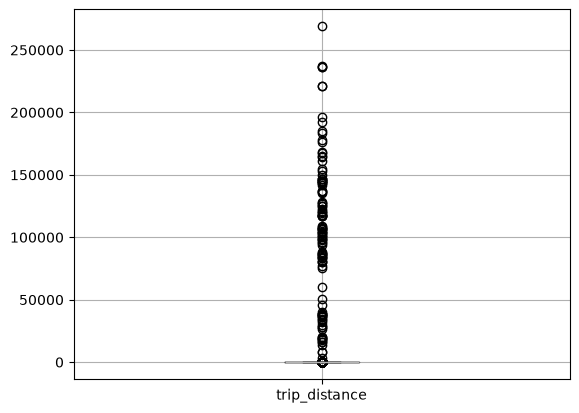

In [62]:
yellow_trip_data[['trip_distance']].boxplot()

In [63]:
yellow_trip_data[['trip_distance']].describe()

,trip_distance
count,"3,724,889.00"
mean,6.46
std,648.89
min,0.00
25%,1.00
50%,1.81
75%,3.73
max,"269,097.48"


In [64]:
(yellow_trip_data['trip_distance'] > 1000).sum()

np.int64(111)

There are definitely a questionable amount of trips where the trip distance is overly long.

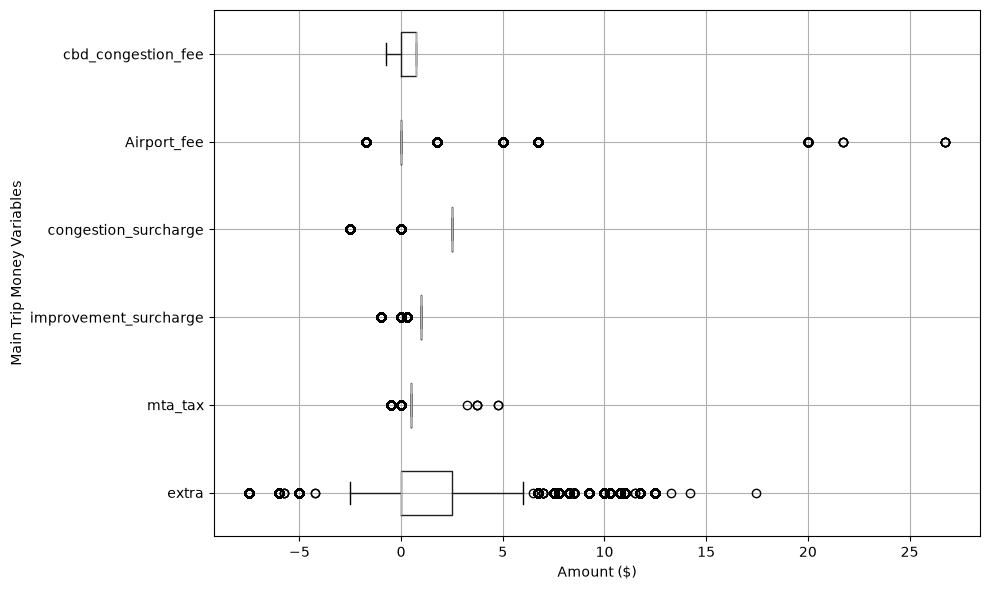

In [65]:
# Investigating on the outliers for the money columns
# firt picture will include most columns besides total amount, fare amount, toll amount, tip amount

yellow_trip_data[[
    'extra',
    'mta_tax',
    'improvement_surcharge',
    'congestion_surcharge',
    'Airport_fee',
    'cbd_congestion_fee']].boxplot(
    vert=False,
    figsize=(10,6)
)

plt.xlabel("Amount ($)")
plt.ylabel("Main Trip Money Variables")
plt.tight_layout()
plt.show()

There are some negative values in all of these columns but on the positive sides the values are reasonable.

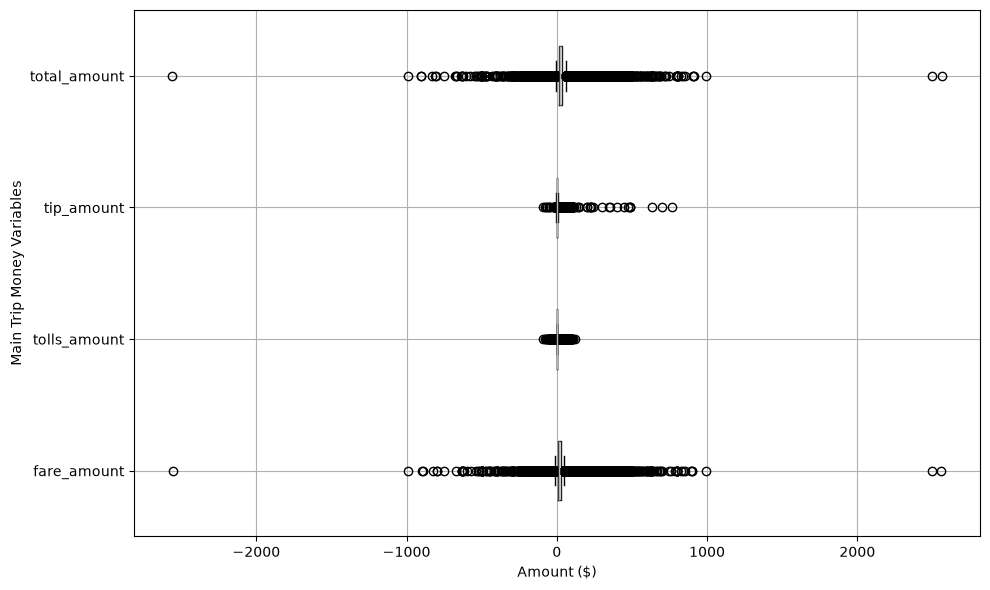

In [66]:
yellow_trip_data[['fare_amount',
                  'tolls_amount',
                  'tip_amount',
                  'total_amount']].boxplot(
                      vert=False,
                      figsize=(10,6)
                  )

plt.xlabel("Amount ($)")
plt.ylabel("Main Trip Money Variables")
plt.tight_layout()
plt.show()

There are definitely questionable amount of negative values in this dataset and some values are very extreme which requires further investigation.

## Data Quality Summary

This dataset records information about each trip that took place in the yellow cab in New York Taxi system in Janurary. The unit of observation is a single trip in the taxi.

Through the inspection of the data, there are a couple of things that are worthy of noting.

Passenger Count is in the wrong data type. It is recorded as a float data type.

There are 1088058 rows of data that are missing values for various columns. This can be worthy of noting.

There are some questionable pick up and drop off date time as they are not included in the Janurary Time.

There is one row that the drop off time is earlier than the pick up time.

For the money columns there are lots of rows where the money is negative which is problematic.


## Define Cleaning Rules

* Coerce Passenger Count into Integer Data Types
* Remove those rows with questionable pick up and drop off times
* Remove the row where the drop off time is earlier than the pick up time
* Remove the the rows where the pick up time is outside of January
